# Sprint 3: Análise de desigualdades sociais (escolaridade e raça/cor)

Objetivo:
Atender ao requisito central da Issue de interseccionalidade, cruzando os dados de mortalidade com as variáveis sociodemográficas (`ESC2010` e `RACACOR`) para evidenciar o perfil populacional afetado e eventuais lacunas de preenchimento nos registros oficiais.

In [2]:
import pandas as pd

df = pd.read_csv('../data/processed/sim_sc_processado.csv')

df_ararangua = df[df['CODMUNRES'].astype(str).str.contains('420140', na=False)].copy()

print(f"Total de registros para Araranguá: {len(df_ararangua)}")

colunas_sprint3 = ['CODMUNRES', 'CAUSABAS', 'ESC2010', 'RACACOR', 'IDADE']
df_ararangua = df_ararangua[[c for c in colunas_sprint3 if c in df_ararangua.columns]]

print(df_ararangua.head())

C:\Users\goula\AppData\Local\Temp\ipykernel_18924\763547665.py:3: DtypeWarning: Columns (0: DTOBITO, 1: DTNASC, 2: RACACOR, 3: ESC, 4: IDADEMAE, 5: ESCMAE, 6: GESTACAO, 7: LINHAA, 8: LINHAB, 9: LINHAC, 10: LINHAD, 11: LINHAII, 12: TPPOS, 13: CAUSABAS_O, 14: CB_PRE, 15: CAUSAMAT, 16: STCODIFICA, 17: CODIFICADO, 18: VERSAOSIST, 19: ATESTADO, 20: FONTES, 21: TPNIVELINV, 22: FONTESINF, 23: CB_ALT, 24: OCUPACAO, 25: FILHVIVOS, 26: FILHMORT) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('../data/processed/sim_sc_processado.csv')


Total de registros para Araranguá: 15608
      CODMUNRES CAUSABAS  ESC2010 RACACOR  IDADE
611     4201406     V892      NaN  Branca  445.0
613     4201406     V892      NaN  Branca  435.0
1294    4201406      I64      NaN     NaN  479.0
1301    4201406     O249      NaN  Branca  417.0
2016    4201406     V645      NaN  Branca  460.0


In [3]:
print("... Distribuição por raça/cor ...")
print(df_ararangua['RACACOR'].value_counts(dropna=False))

print("\n... Distribuição por escolaridade (ESC2010) ...")
print(df_ararangua['ESC2010'].value_counts(dropna=False))

... Distribuição por raça/cor ...
RACACOR
Branca      9973
NaN         5158
Parda        248
Preta        212
Amarela       13
Indigena       4
Name: count, dtype: int64

... Distribuição por escolaridade (ESC2010) ...
ESC2010
NaN    10140
1.0     2702
2.0     1033
3.0      704
0.0      581
5.0      212
9.0      186
4.0       50
Name: count, dtype: int64


C:\Users\goula\AppData\Local\Temp\ipykernel_18924\3740385664.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


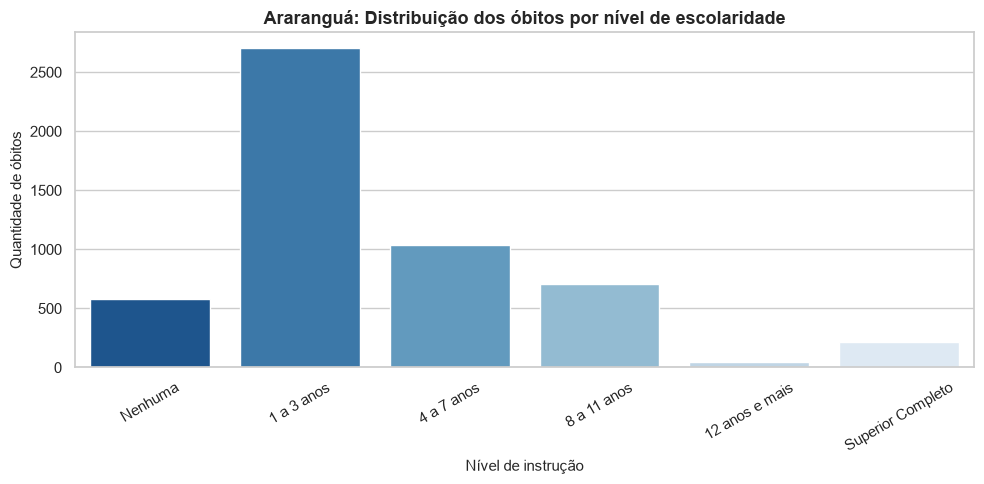

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

df_escolaridade = df_ararangua.dropna(subset=['ESC2010']).copy()

# Tradução dos códigos 
mapeamento_esc = {
    0.0: 'Nenhuma',
    1.0: '1 a 3 anos',
    2.0: '4 a 7 anos',
    3.0: '8 a 11 anos',
    4.0: '12 anos e mais',
    5.0: 'Superior Completo',
    9.0: 'Ignorado'
}
df_escolaridade['NIVEL_INSTRUCAO'] = df_escolaridade['ESC2010'].map(mapeamento_esc)

sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df_escolaridade, 
    x='NIVEL_INSTRUCAO', 
    order=['Nenhuma', '1 a 3 anos', '4 a 7 anos', '8 a 11 anos', '12 anos e mais', 'Superior Completo'],
    palette='Blues_r'
)

plt.title('Araranguá: Distribuição dos óbitos por nível de escolaridade', fontsize=13, fontweight='bold')
plt.xlabel('Nível de instrução', fontsize=11)
plt.ylabel('Quantidade de óbitos', fontsize=11)
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

C:\Users\goula\AppData\Local\Temp\ipykernel_18924\824971687.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


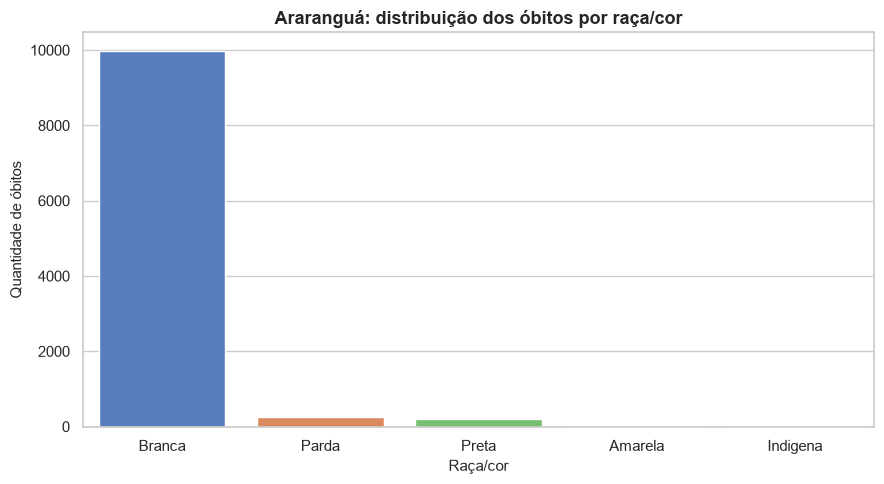

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Limpando os valores vazios de raça/cor 
df_raca = df_ararangua.dropna(subset=['RACACOR']).copy()

sns.set_theme(style="whitegrid")
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df_raca, 
    x='RACACOR', 
    order=df_raca['RACACOR'].value_counts().index,
    palette='muted'
)

plt.title('Araranguá: distribuição dos óbitos por raça/cor', fontsize=13, fontweight='bold')
plt.xlabel('Raça/cor', fontsize=11)
plt.ylabel('Quantidade de óbitos', fontsize=11)

plt.tight_layout()
plt.show()

In [10]:
def classificar_evitabilidade_detalhada(causa):
    if pd.isna(causa):
        return 'Mal Definidos / Ignorados'
    causa_str = str(causa).upper()
    if causa_str.startswith(('A', 'B')): return 'Infecciosas e Parasitárias'
    elif causa_str.startswith(('C', 'D')): return 'Neoplasias (Tumores)'
    elif causa_str.startswith('E'): return 'Endócrinas e Metabólicas'
    elif causa_str.startswith('I'): return 'Doenças do Aparelho Circulatório'
    elif causa_str.startswith('J'): return 'Doenças do Aparelho Respiratório'
    elif causa_str.startswith(('V', 'W', 'X', 'Y')): return 'Causas Externas'
    else: return 'Outras Causas Específicas'

# Cruzamento de causa de morte x escolaridade
df_cruzamento = df_ararangua.dropna(subset=['ESC2010', 'CAUSABAS']).copy()
df_cruzamento['GRUPO_CAUSA'] = df_cruzamento['CAUSABAS'].apply(classificar_evitabilidade_detalhada)

mapeamento_esc_tabela = {
    0.0: 'Nenhuma', 1.0: '1-3 anos', 2.0: '4-7 anos', 
    3.0: '8-11 anos', 4.0: '12+ anos', 5.0: 'Superior', 9.0: 'Ignorado'
}
df_cruzamento['ESCOLARIDADE'] = df_cruzamento['ESC2010'].map(mapeamento_esc_tabela)

tabela_impacto = pd.crosstab(df_cruzamento['GRUPO_CAUSA'], df_cruzamento['ESCOLARIDADE'])
print("\n=== MATRIZ DE HIERARQUIA DE IMPACTO (Causa vs. Escolaridade) ===")
print(tabela_impacto)

# Comparando Araranguá com Criciúma (420460)

df_completo = pd.read_csv('../data/processed/sim_sc_processado.csv')
municipios_foco = df_completo[df_completo['CODMUNRES'].astype(str).str.contains('420140|420460', na=False)].copy()

def rotular_municipio(codigo):
    return 'Araranguá' if '420140' in str(codigo) else 'Criciúma'

municipios_foco['MUNICIPIO'] = municipios_foco['CODMUNRES'].apply(rotular_municipio)
municipios_foco['GRUPO_CAUSA'] = municipios_foco['CAUSABAS'].apply(classificar_evitabilidade_detalhada)

tabela_territorio = pd.crosstab(municipios_foco['GRUPO_CAUSA'], municipios_foco['MUNICIPIO'])
print(tabela_territorio)


=== MATRIZ DE HIERARQUIA DE IMPACTO (Causa vs. Escolaridade) ===
ESCOLARIDADE                      1-3 anos  12+ anos  4-7 anos  8-11 anos  \
GRUPO_CAUSA                                                                 
Causas Externas                         79         6       124         82   
Doenças do Aparelho Circulatório       946         9       309        173   
Doenças do Aparelho Respiratório       405         4       102         77   
Endócrinas e Metabólicas               196         2        57         33   
Infecciosas e Parasitárias             179         6        99         77   
Neoplasias (Tumores)                   547        16       224        172   
Outras Causas Específicas              350         7       118         90   

ESCOLARIDADE                      Ignorado  Nenhuma  Superior  
GRUPO_CAUSA                                                    
Causas Externas                         46        8        19  
Doenças do Aparelho Circulatório        43      

C:\Users\goula\AppData\Local\Temp\ipykernel_18924\1169113458.py:29: DtypeWarning: Columns (0: DTOBITO, 1: DTNASC, 2: RACACOR, 3: ESC, 4: IDADEMAE, 5: ESCMAE, 6: GESTACAO, 7: LINHAA, 8: LINHAB, 9: LINHAC, 10: LINHAD, 11: LINHAII, 12: TPPOS, 13: CAUSABAS_O, 14: CB_PRE, 15: CAUSAMAT, 16: STCODIFICA, 17: CODIFICADO, 18: VERSAOSIST, 19: ATESTADO, 20: FONTES, 21: TPNIVELINV, 22: FONTESINF, 23: CB_ALT, 24: OCUPACAO, 25: FILHVIVOS, 26: FILHMORT) have mixed types. Specify dtype option on import or set low_memory=False.
  df_completo = pd.read_csv('../data/processed/sim_sc_processado.csv')


MUNICIPIO                         Araranguá  Criciúma
GRUPO_CAUSA                                          
Causas Externas                        1226      3144
Doenças do Aparelho Circulatório       3640     10835
Doenças do Aparelho Respiratório       1336      3741
Endócrinas e Metabólicas                648      1250
Infecciosas e Parasitárias              676      2287
Neoplasias (Tumores)                   2067      6400
Outras Causas Específicas              6015     16514


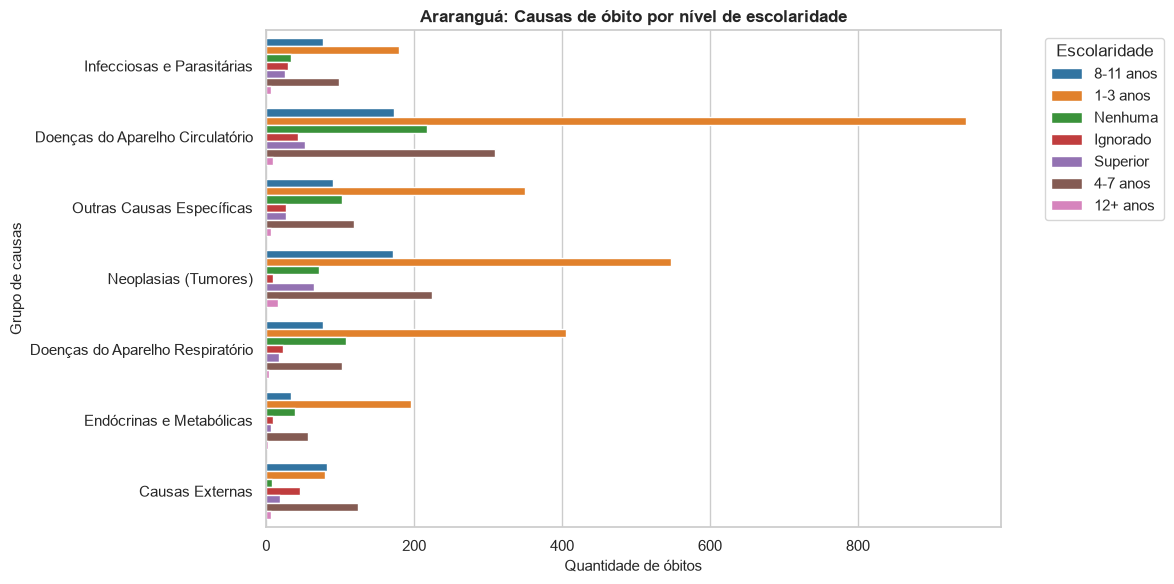

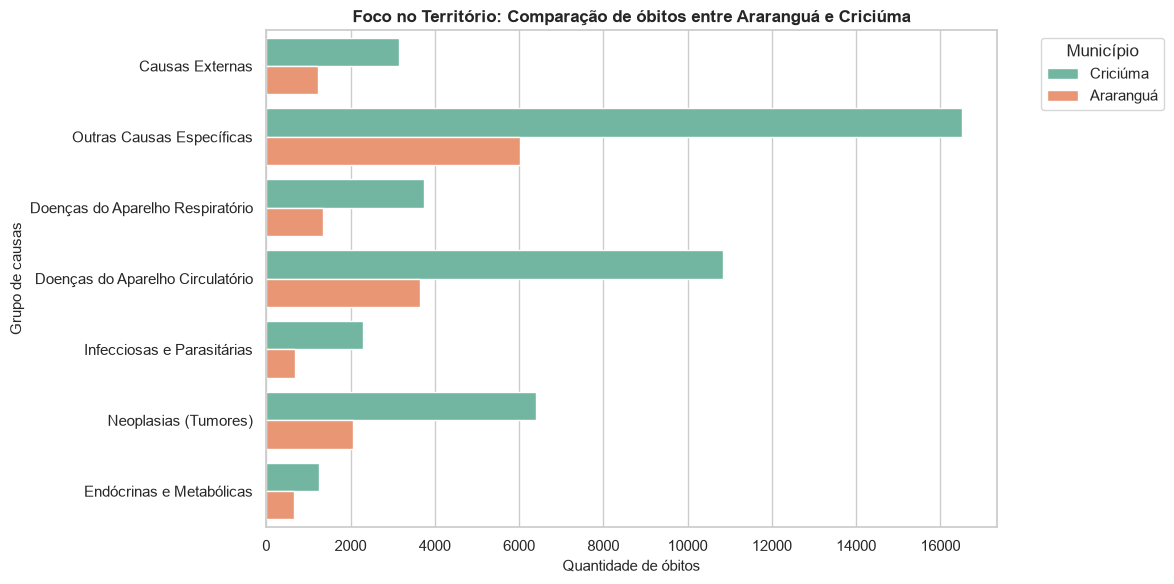

In [13]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))
df_cruzamento = df_ararangua.dropna(subset=['ESC2010']).copy()
mapeamento_esc = {0.0: 'Nenhuma', 1.0: '1-3 anos', 2.0: '4-7 anos', 3.0: '8-11 anos', 4.0: '12+ anos', 5.0: 'Superior', 9.0: 'Ignorado'}
df_cruzamento['ESCOLARIDADE'] = df_cruzamento['ESC2010'].map(mapeamento_esc)

sns.countplot(
    data=df_cruzamento, 
    y='GRUPO_CAUSA', 
    hue='ESCOLARIDADE', 
    palette='tab10'
)
plt.title('Araranguá: Causas de óbito por nível de escolaridade', fontsize=12, fontweight='bold')
plt.xlabel('Quantidade de óbitos', fontsize=11)
plt.ylabel('Grupo de causas', fontsize=11)
plt.legend(title='Escolaridade', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

# Araranguá vs Criciúma
plt.figure(figsize=(12, 6))
municipios_foco = df[df['CODMUNRES'].astype(str).str.contains('420140|420460', na=False)].copy()

def rotular_municipio(codigo):
    return 'Araranguá' if '420140' in str(codigo) else 'Criciúma'

municipios_foco['MUNICIPIO'] = municipios_foco['CODMUNRES'].apply(rotular_municipio)
municipios_foco['GRUPO_CAUSA'] = municipios_foco['CAUSABAS'].apply(classificar_evitabilidade_detalhada)

sns.countplot(
    data=municipios_foco, 
    y='GRUPO_CAUSA', 
    hue='MUNICIPIO', 
    palette='Set2'
)
plt.title('Foco no Território: Comparação de óbitos entre Araranguá e Criciúma', fontsize=12, fontweight='bold')
plt.xlabel('Quantidade de óbitos', fontsize=11)
plt.ylabel('Grupo de causas', fontsize=11)
plt.legend(title='Município', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()